<a href="https://colab.research.google.com/github/AnjiReddyDondeti/Credit-Card-Fraud-Detection-/blob/main/E_signature.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image
plt.rcParams['figure.figsize'] = (6.0, 6.0)
plt.rcParams['image.cmap'] = 'gray'

if 'google.colab' in str(get_ipython()):
    print("Downloading Code to Colab Environment")
    !wget https://www.dropbox.com/sh/f8ae3j0nbrflife/AAAy-WwcREtWOGgoEbFLDPANa?dl=1 -O module-code.zip -q --show-progress
    !unzip -qq module-code.zip
    %cd Applications/
else:
    pass

module-code.zip     100%[===================>]  21.78M  7.57MB/s    in 2.9s    
mapname:  conversion of  failed
/content/Applications


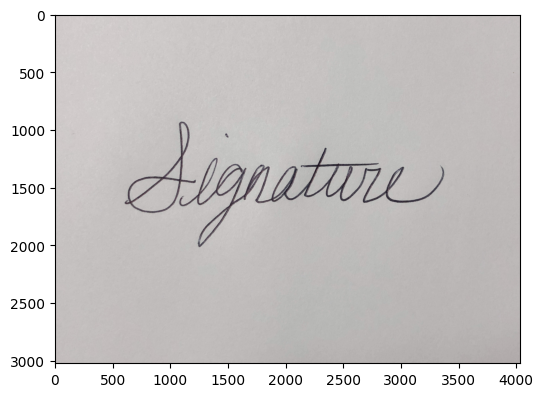

In [2]:
sign = cv2.imread('/content/signature.jpg', cv2.IMREAD_COLOR)
plt.imshow(sign[:,:,::-1])

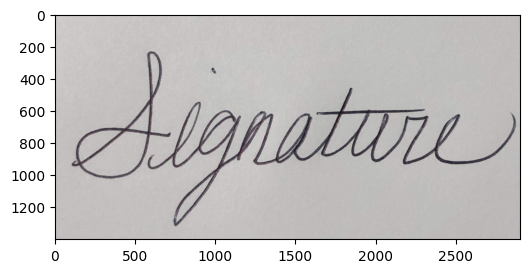

In [4]:
# crop the signature from the original image
sign_crop = sign[700:2100, 500:3400, :]
plt.imshow(sign_crop[:,:,::-1])

(1400, 2900) uint8 2


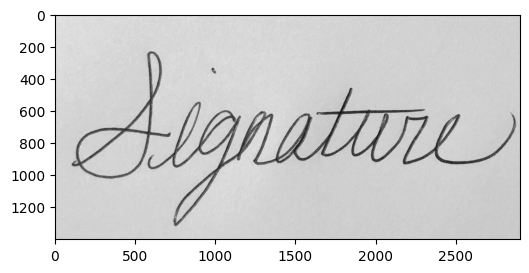

In [5]:
# converting into gray scale
sign_gray = cv2.cvtColor(sign_crop, cv2.COLOR_BGR2GRAY)
plt.imshow(sign_gray)
print(sign_gray.shape, sign_gray.dtype, sign_gray.ndim)

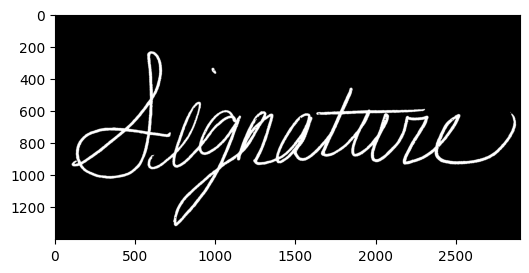

In [10]:
# creating alpha mask
ret, threshold = cv2.threshold(sign_gray, 150, 255, cv2.THRESH_BINARY_INV)
plt.imshow(threshold)

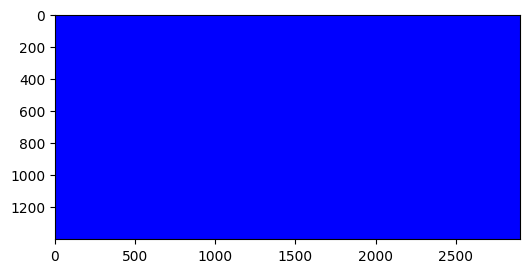

In [13]:
blue_mask = sign_crop.copy()
blue_mask[:, :] = (255, 0, 0)
plt.imshow(blue_mask[:, :, ::-1])

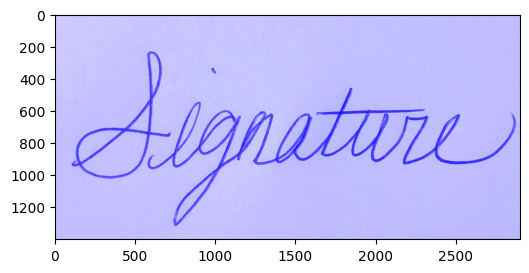

In [14]:
sign_blue_color = cv2.addWeighted(sign_crop, 1, blue_mask, 1, 0)
plt.imshow(sign_blue_color[:,:,::-1])

In [17]:
# splitting color channels from color image
b, g, r = cv2.split(sign_blue_color)
print(b.shape)
print(g.shape)
print(r.shape)

(1400, 2900)
(1400, 2900)
(1400, 2900)


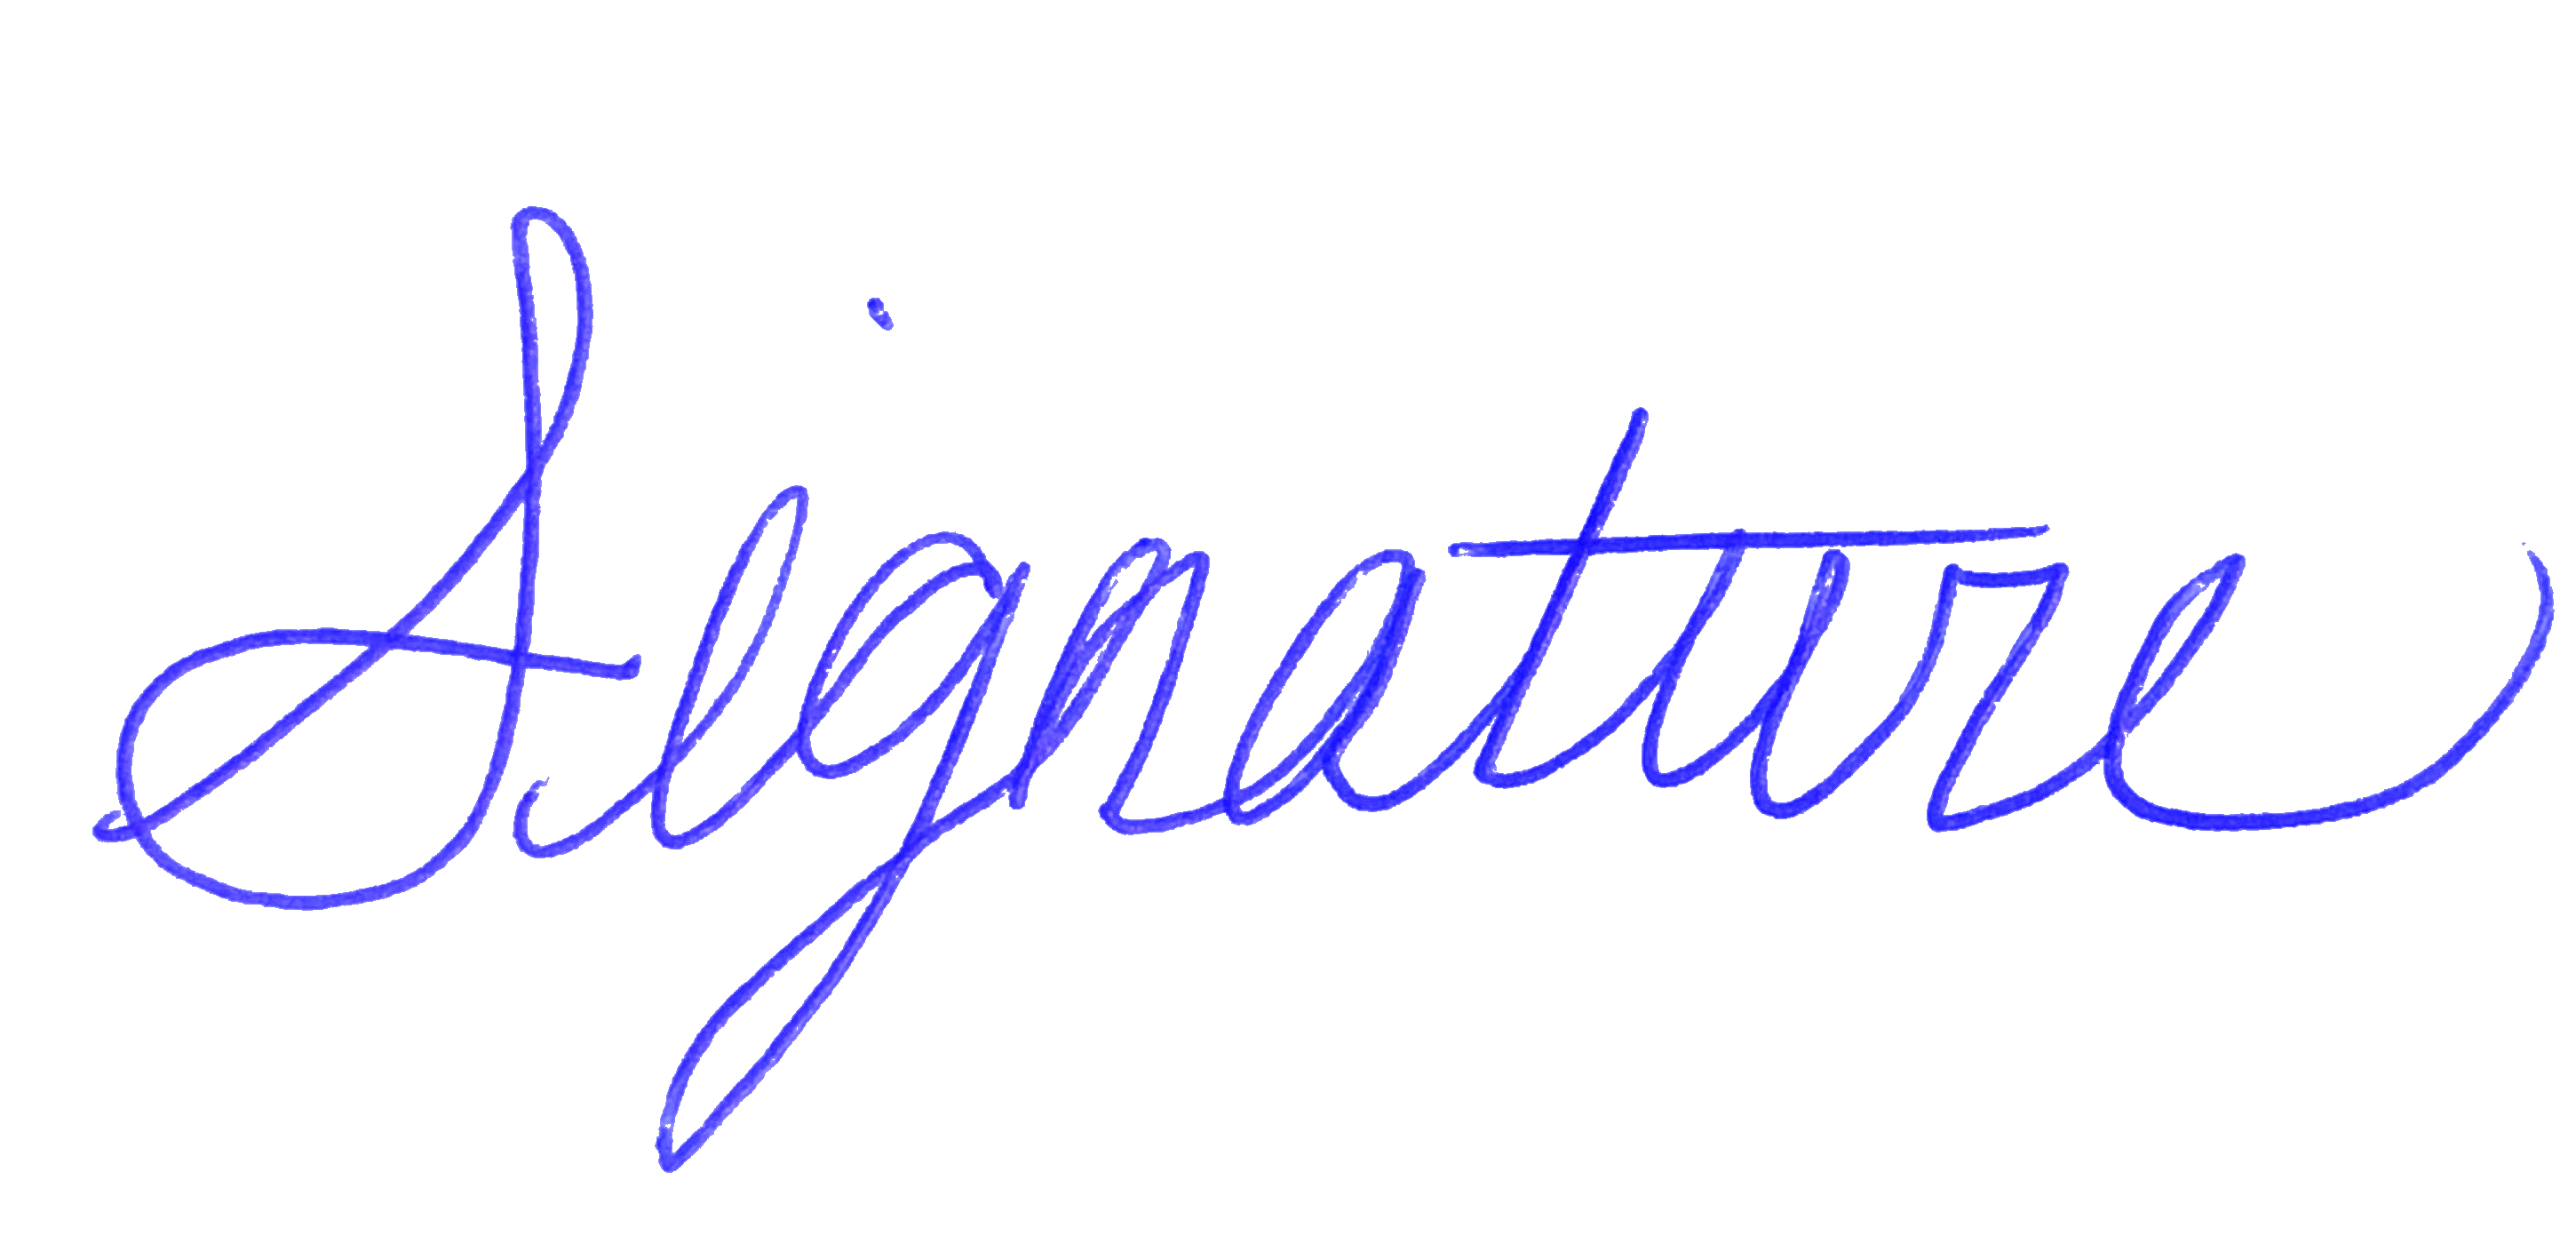

In [19]:
# Merging the alpha channel with BGR
new_list = [b, g, r, threshold]
png = cv2.merge(new_list, 4)
# saving the image file
cv2.imwrite('new signature.png', png)
Image('new signature.png')